# Assignment 2 — Covariance, VaR, and Copulas

All risk numbers use $\alpha = 5\%$ unless stated otherwise and are reported as positive losses.
Functions from the course `Library/` package are imported through `Risk_Library`; anything the
library does not provide is written inline below and flagged with **(not in Library)**.

In [1]:
"""Setup: imports, path to the shared Library package, and display options."""
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# The Library lives one folder up from Assignment2/. Adding it to sys.path lets us
# import the aggregated entry point `Risk_Library`.
sys.path.insert(0, "../Library")
from Risk_Library import (
    covariance_matrix, fix_psd_matrix, cholesky_psd,          # Problem 1
    return_calculate, ew_covariance_matrix,                   # Problem 2
    fit_t_distribution, calculate_var,
)

pd.set_option("display.precision", 4)
pd.set_option("display.width", 150)

# Figures are also saved to disk so they can be dropped into the written report.
os.makedirs("figures", exist_ok=True)

# Problem 1 — Correlations from Mismatched Histories

## Predict

First, look at the missing-data pattern before touching any correlation.

In [2]:
"""Load the data and inspect when each series trades."""
p1 = pd.read_csv("problem1.csv", index_col="Day")

# First/last trading day and number of observations per series.
coverage = pd.DataFrame({
    "first_day": p1.apply(lambda s: s.first_valid_index()),
    "last_day": p1.apply(lambda s: s.last_valid_index()),
    "n_obs": p1.notna().sum(),
})
coverage

,first_day,last_day,n_obs
A,1,250,242
B,1,250,242
C,1,250,228
D,151,250,96
IDX,1,250,250


In [3]:
def joint_observation_counts(data: pd.DataFrame) -> pd.DataFrame:
    """(not in Library) Number of days each pair of columns is jointly observed.

    With an indicator matrix O (1 = observed), O.T @ O counts, for every pair (i, j),
    the rows where both i and j are non-missing. The diagonal is each series' own count.
    """
    observed = data.notna().astype(int)
    return observed.T @ observed


p1_joint = joint_observation_counts(p1)
n_all_five = len(p1.dropna())   # rows where every series trades
print(f"Days on which all five series trade: {n_all_five} of {len(p1)}")
p1_joint

Days on which all five series trade: 81 of 250


,A,B,C,D,IDX
A,242,242,221,93,242
B,242,242,221,93,242
C,221,221,228,83,228
D,93,93,83,96,96
IDX,242,242,228,96,250


**What the table shows.** `IDX` trades all 250 days, `A`/`B` miss the same 8 days, `C` misses 22 days
(a different set of holidays), and `D` only exists from day 151 (96 days). Only **81** days have all five.
The pairwise counts therefore range from 242 (`A`–`B`) down to **83** (`C`–`D`).

**(a) Which estimator can fail PSD?**
*Complete case* is guaranteed PSD: every entry is computed on the same 81 rows, so the matrix is the
sample correlation of one data matrix $X$, i.e. $\frac{1}{n-1}Z^\top Z$ for standardized $Z$, and
$w^\top Z^\top Z w = \lVert Zw\rVert^2 \ge 0$ for every $w$.
*Pairwise* can fail: each entry comes from a different subset of days, so the entries are not the
correlations of any single data set. Nothing ties them together, and the matrix can imply a portfolio with negative variance.

**(b) What does IDX being almost a linear combination imply?**
If $IDX \approx 0.4A + 0.3B + 0.2C + 0.1D$, the portfolio $w = (-0.4, -0.3, -0.2, -0.1, 1)$ has almost
zero variance (only the tracking error). In correlation units that means the **true smallest eigenvalue
is very close to zero** (just positive). A matrix whose smallest eigenvalue sits that close to zero has no
room to absorb estimation error: small inconsistencies between pairwise entries are enough to push it
negative. So this data set is **highly exposed** to the pairwise failure, more than a typical set of
five stocks would be.

**(c) Least reliable correlations.**
Those involving `D`, and most of all **`C`–`D` (83 days)**, then `D` with `A`/`B` (93) and `D`–`IDX` (96).
The standard error of a correlation is roughly $1/\sqrt{n}$: about 0.11 for 83 days against 0.065 for 242.
They are also measured only over the second part of the sample (days 151–250), while `A`–`B`–`C`
pairs use the whole year, so if correlations shift over time the `D` entries describe a different period.

## Fit

### (d) Complete-case vs pairwise correlation, eigenvalues, Cholesky

In [4]:
"""Both correlation matrices come from the Library; only the missing-data option differs."""
corr_cc = covariance_matrix(p1, method="correlation", missing_strategy="drop_row")   # 81 common rows
corr_pw = covariance_matrix(p1, method="correlation", missing_strategy="pairwise")   # each pair on its own rows

print("Complete-case correlation:")
display(corr_cc)
print("Pairwise correlation:")
display(corr_pw)

Complete-case correlation:


,A,B,C,D,IDX
A,1.0000,0.3967,0.2466,0.4136,0.8714
B,0.3967,1.0000,0.3169,0.2361,0.6709
C,0.2466,0.3169,1.0000,0.1852,0.5648
D,0.4136,0.2361,0.1852,1.0000,0.5719
IDX,0.8714,0.6709,0.5648,0.5719,1.0000


Pairwise correlation:


,A,B,C,D,IDX
A,1.0000,0.4686,0.4309,0.4384,0.8696
B,0.4686,1.0000,0.4630,0.2767,0.7329
C,0.4309,0.4630,1.0000,0.1846,0.7136
D,0.4384,0.2767,0.1846,1.0000,0.6057
IDX,0.8696,0.7329,0.7136,0.6057,1.0000


In [5]:
def eigenvalues(matrix: pd.DataFrame) -> np.ndarray:
    """(not in Library) Eigenvalues of a symmetric matrix, sorted ascending (eigvalsh assumes symmetry)."""
    return np.linalg.eigvalsh(matrix.values)


eig_table = pd.DataFrame({
    "complete_case": eigenvalues(corr_cc),
    "pairwise": eigenvalues(corr_pw),
})
eig_table

,complete_case,pairwise
0,0.0015,-0.0111
1,0.5483,0.4714
2,0.6933,0.5284
3,0.8704,0.8574
4,2.8864,3.1539


In [6]:
def try_cholesky(matrix: pd.DataFrame, name: str) -> None:
    """Attempt a Cholesky factorization two ways and report what happens.

    1. numpy's strict Cholesky: requires positive DEFINITE and raises LinAlgError otherwise.
    2. Library `cholesky_psd`: tolerates zero pivots (PSD), but a clearly negative pivot
       gives sqrt(negative) = NaN, which is how a non-PSD input shows up there.
    """
    try:
        np.linalg.cholesky(matrix.values)
        print(f"{name}: numpy Cholesky succeeded.")
    except np.linalg.LinAlgError as err:
        print(f"{name}: numpy Cholesky FAILED -> {err}")

    with np.errstate(invalid="ignore"):          # silence the sqrt(negative) warning; we inspect the result
        root = cholesky_psd(matrix)
    last_pivot = root.values[-1, -1]               # diagonal entry for IDX, the last column
    print(f"{name}: Library cholesky_psd IDX pivot L[IDX,IDX] = {last_pivot:.4f}, "
          f"contains NaN: {root.isna().values.any()}\n")


try_cholesky(corr_cc, "Complete case")
try_cholesky(corr_pw, "Pairwise")

Complete case: numpy Cholesky succeeded.
Complete case: Library cholesky_psd IDX pivot L[IDX,IDX] = 0.0486, contains NaN: False

Pairwise: numpy Cholesky FAILED -> Matrix is not positive definite
Pairwise: Library cholesky_psd IDX pivot L[IDX,IDX] = nan, contains NaN: True



The complete-case matrix factors, but its last pivot (IDX) is only about 0.05. Once A–D are known, IDX has very
little variance left over, which is the near-linear-dependence from (b). The pairwise matrix has a
**negative eigenvalue (−0.011)**, so strict Cholesky fails and the Library routine gives `NaN` at the IDX pivot.

### (e) Tracking-portfolio variance from the pairwise covariance

In [7]:
def corr_to_cov(corr: pd.DataFrame, std: pd.Series) -> pd.DataFrame:
    """(not in Library) Covariance = D @ R @ D with D = diag(std). Done element-wise via an outer product."""
    return corr * np.outer(std, std)


def portfolio_variance(cov: pd.DataFrame, weights: pd.Series) -> float:
    """(not in Library) Portfolio variance w' Σ w (Week 2), with weights aligned to the covariance labels."""
    w = weights.reindex(cov.columns).values
    return float(w @ cov.values @ w)


# Full-history standard deviation of each series: each column uses all of its own non-missing days.
p1_std = p1.std()

# Long 1 unit of IDX, short the fixed-weight basket 0.4A + 0.3B + 0.2C + 0.1D.
w_track = pd.Series({"A": -0.4, "B": -0.3, "C": -0.2, "D": -0.1, "IDX": 1.0})

cov_pw = corr_to_cov(corr_pw, p1_std)
var_track_pw = portfolio_variance(cov_pw, w_track)
print(f"Tracking-portfolio variance (pairwise covariance): {var_track_pw:.4e}")

# Benchmarks for reference: same std's with the complete-case correlation, and the
# realized variance of the tracking portfolio on the 81 days where all five trade.
var_track_cc = portfolio_variance(corr_to_cov(corr_cc, p1_std), w_track)
var_track_realized = (p1.dropna() @ w_track.reindex(p1.columns)).var()
print(f"Tracking-portfolio variance (complete-case corr):  {var_track_cc:.4e}")
print(f"Realized tracking variance (81 complete days):     {var_track_realized:.4e}  "
      f"(daily TE std = {np.sqrt(var_track_realized):.4%})")

Tracking-portfolio variance (pairwise covariance): -1.7994e-06
Tracking-portfolio variance (complete-case corr):  1.0975e-06
Realized tracking variance (81 complete days):     3.2221e-07  (daily TE std = 0.0568%)


**The pairwise covariance gives the tracking portfolio a negative variance (≈ −1.8e−6).** That is impossible for a real
portfolio. The realized tracking variance is ≈ 3.2e−7 (a daily tracking error of about 0.06%).

### (f) Repair with Rebonato–Jäckel and Higham

In [8]:
def frobenius_distance(a: pd.DataFrame, b: pd.DataFrame) -> float:
    """(not in Library) Frobenius norm of the difference: sqrt(sum of squared element differences)."""
    return float(np.linalg.norm(a.values - b.values, ord="fro"))


# Library repairs: "near_psd" = Rebonato & Jäckel eigenvalue clipping, "higham" = alternating projections.
corr_rj = fix_psd_matrix(corr_pw, method="near_psd")
corr_hi = fix_psd_matrix(corr_pw, method="higham")

repair_summary = pd.DataFrame({
    name: {
        "smallest eigenvalue": eigenvalues(m)[0],
        "Frobenius dist. from pairwise": frobenius_distance(m, corr_pw),
        "tracking variance": portfolio_variance(corr_to_cov(m, p1_std), w_track),
    }
    for name, m in [("pairwise (unrepaired)", corr_pw),
                    ("Rebonato-Jackel", corr_rj),
                    ("Higham", corr_hi)]
}).T
repair_summary

,smallest eigenvalue,Frobenius dist. from pairwise,tracking variance
pairwise (unrepaired),-1.1072e-02,0.0000,-1.7994e-06
Rebonato-Jackel,3.5869e-17,0.0162,6.8073e-07
Higham,-4.8980e-10,0.0155,6.7876e-07


Both repairs push the smallest eigenvalue to about zero. Higham's −5e−10 is zero to within its convergence tolerance.
Higham is slightly closer to the original (0.0155 vs 0.0162), as expected, because it solves for the nearest PSD matrix
directly. The tracking variance becomes **positive, ≈ 6.8e−7** under both repairs. That is about twice the
realized 3.2e−7, but at least it is a real variance.

## Reconcile

### (g) Why the variance in (e) was negative
PSD means $w^\top \Sigma w \ge 0$ for **every** vector $w$, which is the same as saying every
portfolio has non-negative variance. Equivalently, all eigenvalues are $\ge 0$, because
$w^\top\Sigma w = \sum_k \lambda_k (v_k^\top w)^2$. The pairwise matrix has $\lambda_{\min} = -0.011$, so any
portfolio pointing along that eigenvector gets negative variance. The tracking portfolio is
almost exactly that direction: it was built to cancel almost all the risk, so it lines up with the near-zero eigenvector from (b).
The cell below checks this.

In [9]:
"""Compare the eigenvector of the negative eigenvalue with the tracking portfolio (in correlation units)."""
vals_pw, vecs_pw = np.linalg.eigh(corr_pw.values)
v_min = pd.Series(vecs_pw[:, 0], index=corr_pw.columns)
v_min = v_min / v_min["IDX"]                       # scale so the IDX loading is 1

# The tracking weights act on returns; in correlation units weight_i * std_i is the comparable vector.
w_track_corr_units = w_track * p1_std
w_track_corr_units = w_track_corr_units / w_track_corr_units["IDX"]

pd.DataFrame({"eigenvector of λ_min (IDX=1)": v_min,
              "tracking portfolio in corr units (IDX=1)": w_track_corr_units})

,eigenvector of λ_min (IDX=1),tracking portfolio in corr units (IDX=1)
A,-0.4798,-0.5375
B,-0.2843,-0.2911
C,-0.3247,-0.2984
D,-0.2539,-0.1859
IDX,1.0000,1.0000


The two vectors have the same signs and similar sizes. The pairwise estimator put its error in the one direction that
matters most for this portfolio.

### (h) Which entries did Higham move most?

In [10]:
"""Element-wise change made by each repair, and the largest moves ranked (upper triangle only)."""
delta_hi = corr_hi - corr_pw
delta_rj = corr_rj - corr_pw
print("Higham minus pairwise:")
display(delta_hi)

iu = np.triu_indices(len(corr_pw), k=1)            # off-diagonal pairs, each counted once
pairs = [f"{corr_pw.columns[i]}-{corr_pw.columns[j]}" for i, j in zip(*iu)]
moves = pd.DataFrame({
    "Higham change": delta_hi.values[iu],
    "R-J change": delta_rj.values[iu],
    "joint obs": p1_joint.values[iu],
}, index=pairs).sort_values("Higham change", key=np.abs, ascending=False)
moves

Higham minus pairwise:


,A,B,C,D,IDX
A,0.0000,0.0020,0.0023,0.0018,-0.0070
B,0.0020,0.0000,0.0014,0.0011,-0.0042
C,0.0023,0.0014,0.0000,0.0012,-0.0048
D,0.0018,0.0011,0.0012,0.0000,-0.0037
IDX,-0.0070,-0.0042,-0.0048,-0.0037,0.0000


,Higham change,R-J change,joint obs
A-IDX,-0.0070,-0.0075,242
C-IDX,-0.0048,-0.0054,228
B-IDX,-0.0042,-0.0051,242
D-IDX,-0.0037,-0.0043,96
A-C,0.0023,0.0006,221
A-B,0.0020,0.0005,242
A-D,0.0018,0.0004,93
B-C,0.0014,0.0004,221
C-D,0.0012,0.0005,83
B-D,0.0011,0.0004,93


**Higham moved the IDX entries most** (A–IDX −0.007, C–IDX −0.005, B–IDX −0.004, D–IDX −0.004) and barely changed
the D entries (+0.001 to +0.002). **This does not match my prediction in (c).** I expected the thinly observed C–D (83 days) and
D pairs to be the least reliable and so the ones to fix. C–D was moved by only about 0.001.

The repair knows nothing about sample sizes. It only looks at the **geometry of the matrix**: it finds the
eigen-direction with the negative eigenvalue and makes the smallest Frobenius-norm change that brings it back to zero. That
eigenvector is dominated by IDX (loading 0.82, see (g)), so the correction lands mostly on the IDX row
and column. Every entry is treated as equally trustworthy. A weighted Higham, with weights from the joint
observation counts, could make it move the noisy entries instead.

### (i) Estimator choice vs repair choice

In [11]:
"""Size of the two decisions, measured in the same Frobenius norm."""
gap_estimator = frobenius_distance(corr_cc, corr_pw)
gap_repair = frobenius_distance(corr_hi, corr_rj)
print(f"Complete case vs pairwise:        {gap_estimator:.4f}")
print(f"Pairwise -> Higham repair size:   {frobenius_distance(corr_hi, corr_pw):.4f}")
print(f"Higham vs Rebonato-Jackel:        {gap_repair:.4f}")
print(f"Estimator gap / repair size:      {gap_estimator / frobenius_distance(corr_hi, corr_pw):.0f}x")
display(corr_pw - corr_cc)

Complete case vs pairwise:        0.4239
Pairwise -> Higham repair size:   0.0155
Higham vs Rebonato-Jackel:        0.0046
Estimator gap / repair size:      27x


,A,B,C,D,IDX
A,0.0000,0.0719,0.1843,0.0249,-0.0018
B,0.0719,0.0000,0.1461,0.0406,0.0620
C,0.1843,0.1461,0.0000,-0.0006,0.1487
D,0.0249,0.0406,-0.0006,0.0000,0.0338
IDX,-0.0018,0.0620,0.1487,0.0338,0.0000


In [12]:
"""Why are the two estimators so far apart? D only exists from day 151, so complete case
uses the second part of the year only. Compare correlations before and after day 151."""
cols = ["A", "B", "C", "IDX"]
print("Days 1-150:")
display(p1.loc[:150, cols].corr())
print("Days 151-250:")
display(p1.loc[151:, cols].corr())

Days 1-150:


,A,B,C,IDX
A,1.0000,0.4890,0.5317,0.8789
B,0.4890,1.0000,0.5151,0.7386
C,0.5317,0.5151,1.0000,0.7854
IDX,0.8789,0.7386,0.7854,1.0000


Days 151-250:


,A,B,C,IDX
A,1.0000,0.4173,0.2700,0.8541
B,0.4173,1.0000,0.3781,0.7145
C,0.2700,0.3781,1.0000,0.5804
IDX,0.8541,0.7145,0.5804,1.0000


The gap between the estimators (Frobenius 0.42) is about **27 times** the size of the repair (0.016), and the two
repairs differ from each other by even less. **For this data the choice of estimator matters far more than the choice of repair.**

The diagnostic explains why. Correlations are not stable over the year: C's correlation with A drops from about 0.53
(days 1–150) to about 0.27 (days 151–250). Complete case uses only days 151–250, because D does not exist before then.
Pairwise mixes periods: the A–B–C–IDX entries average over the whole year while the D entries come from the second part
only. That mixing is what makes the pairwise matrix internally inconsistent and non-PSD. A repair can only remove the
inconsistency. It cannot tell us which period's correlations we actually want, and that is the real decision here.

# Problem 2 — A Volatility Estimate After the Regime Changed

$1,000,000 position, one-day VaR at 5%.

## Predict

In [13]:
"""Arithmetic returns via the Library, then remove the sample mean (as the problem instructs)."""
p2_prices = pd.read_csv("problem2.csv")
p2_ret = return_calculate(p2_prices, method="arithmetic", date_column="Day")["Price"]
p2_r = p2_ret - p2_ret.mean()          # demeaned returns; every estimate below uses these
p2_n = len(p2_r)
POSITION = 1_000_000
print(f"{p2_n} returns from {len(p2_prices)} prices")

500 returns from 501 prices


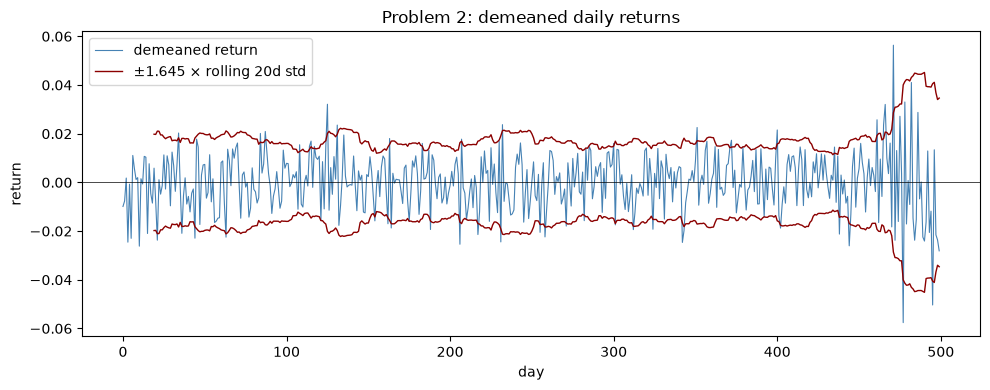

In [14]:
"""Plot the demeaned returns with a rolling 20-day standard deviation band to make vol changes visible."""
roll_sd = p2_r.rolling(20).std()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(p2_r.values, lw=0.8, color="steelblue", label="demeaned return")
ax.plot(1.645 * roll_sd.values, color="darkred", lw=1, label="±1.645 × rolling 20d std")
ax.plot(-1.645 * roll_sd.values, color="darkred", lw=1)
ax.axhline(0, color="black", lw=0.5)
ax.set_xlabel("day"); ax.set_ylabel("return"); ax.set_title("Problem 2: demeaned daily returns")
ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig("figures/p2_returns.png", dpi=150)
plt.show()

**What the plot shows.** The first ~460 days are calm, with daily moves mostly inside ±2% and a steady rolling vol of about 1%.
The **last ~40 days** are clearly different: swings of 3–6% and a rolling vol roughly twice the earlier level.

**(a) Predicted ranking, smallest to largest VaR:**

1. **Student's t (MLE)**: smallest. It is fitted to the whole sample, and the t fit handles the few big days through
   its fat tails (low ν) rather than by inflating its scale. At the 5% level, which is not far into the tail, a fat-tailed t has a
   *smaller* quantile than a normal with the same variance, because more of its mass sits in the center.
2. **Normal, equal-weight σ**: the full-sample σ is a mix of about 460 calm days and 40 volatile ones, so it lands
   only a little above the calm level.
3. **Historical**: the 5% empirical quantile is the 25th worst of 500 days. Many of the worst days are in the recent
   volatile regime, so I expect it slightly above the normal.
4. **Normal, EW λ = 0.97**: most of its weight is on the last ~2 months, so it mostly sees the volatile regime.
5. **Normal, EW λ = 0.94**: largest. It puts even more weight on the most recent, most volatile days.

Items 1–3 should be close together (all see the full sample). Items 4–5 should be far above them, by nearly 2×.

In [15]:
def ew_weights_recent_first(n: int, lam: float) -> np.ndarray:
    """(not in Library as a public function) Normalized EW weights, index 0 = MOST RECENT day.

    w_i ∝ (1-λ) λ^i. Normalizing over the finite sample makes them sum to 1.
    """
    w = (1 - lam) * lam ** np.arange(n)
    return w / w.sum()


def effective_sample_size(w: np.ndarray) -> float:
    """(not in Library) Kish effective sample size 1 / Σ w_i² (→ (1+λ)/(1-λ) for long samples)."""
    return 1.0 / np.sum(w ** 2)


def half_life(lam: float) -> float:
    """(not in Library) Number of days until a weight decays to half: λ^h = 1/2 → h = ln(0.5)/ln(λ)."""
    return np.log(0.5) / np.log(lam)

In [16]:
"""Choose the size of the recent regime. Eyeballing the plot says ~40 days; this check scans every
split k and keeps the one where 'two normals with different σ' fits best (a profile log likelihood)."""
def two_regime_loglik(r: np.ndarray, k: int) -> float:
    """Log likelihood of: first n-k days ~ N(0, s1²), last k days ~ N(0, s2²), with σ's set at their MLE."""
    calm, recent = r[:-k], r[-k:]
    return (stats.norm.logpdf(calm, 0, calm.std()).sum()
            + stats.norm.logpdf(recent, 0, recent.std()).sum())

scan = pd.Series({k: two_regime_loglik(p2_r.values, k) for k in range(10, 151)})
print(f"Best split: last {scan.idxmax()} days (log lik {scan.max():.1f}). Top 5:")
print(scan.sort_values(ascending=False).head().round(2).to_string())

K_RECENT = 40   # from the plot and the scan (39 is best; 35-41 are all within ~1.5 log-lik units)

Best split: last 39 days (log lik 1551.0). Top 5:
39    1551.03
35    1550.35
40    1550.22
36    1549.59
41    1549.40


In [17]:
"""(b) Effective sample size, half life, and the share of total weight placed on the last K_RECENT days."""
p2_lambdas = [0.94, 0.97]
ew_table = pd.DataFrame({
    lam: {
        "effective sample size": effective_sample_size(ew_weights_recent_first(p2_n, lam)),
        "(1+λ)/(1-λ)": (1 + lam) / (1 - lam),
        "half life (days)": half_life(lam),
        f"weight on last {K_RECENT} days": ew_weights_recent_first(p2_n, lam)[:K_RECENT].sum(),
    } for lam in p2_lambdas
}).T
ew_table

,effective sample size,(1+λ)/(1-λ),half life (days),weight on last 40 days
0.94,32.3333,32.3333,11.2023,0.9158
0.97,65.6666,65.6667,22.7566,0.7043


λ = 0.94 has a half life of about 11 days and puts **92%** of its weight on the last 40 days. λ = 0.97 has a half life of
about 23 days and puts **70%** there. So 0.94 is almost entirely a volatile-regime estimate, while 0.97 still gives
about 30% of its weight to the calm period.

In [18]:
"""(c) First four moments of the full sample."""
def four_moments(x: pd.Series) -> pd.Series:
    """(not in Library) Mean, std (ddof=1), skewness, and EXCESS kurtosis (normal = 0), bias-corrected."""
    return pd.Series({
        "mean": x.mean(),
        "std": x.std(ddof=1),
        "skewness": stats.skew(x, bias=False),
        "excess kurtosis": stats.kurtosis(x, fisher=True, bias=False),
    })

p2_moments = four_moments(p2_r)
print(p2_moments.to_string())
# Under normality the sampling SE of excess kurtosis is about sqrt(24/n).
print(f"\nSE of excess kurtosis under normality ≈ sqrt(24/n) = {np.sqrt(24 / p2_n):.3f}"
      f"  -> observed is {p2_moments['excess kurtosis'] / np.sqrt(24 / p2_n):.1f} SEs from 0")

mean              -2.2204e-19
std                1.1912e-02
skewness          -1.5606e-01
excess kurtosis    2.1659e+00

SE of excess kurtosis under normality ≈ sqrt(24/n) = 0.219  -> observed is 9.9 SEs from 0


Mean is 0 by construction, and skew is mildly negative (−0.16). **Excess kurtosis is 2.1**, almost ten standard errors
above the 0 a normal distribution would give. **Prediction: a single normal regime could not produce these moments.** The plot already suggests why: two
normal regimes with different σ, pooled together, give a fat-tailed, peaked distribution.

## Fit — (d) the five VaR estimates

In [19]:
def ew_std_zero_mean(r: pd.Series, lam: float) -> float:
    """(not in Library) EW standard deviation sqrt(Σ w_i r_i²) on the ALREADY-demeaned returns.

    Convention choice: the problem tells us to remove the sample mean first, so the EW variance is
    centered at that (zero) mean. The Library's `ew_covariance_matrix` instead re-centers at the
    EW-weighted mean, which here is pulled toward the recent returns and gives a slightly smaller σ.
    Both are shown below; the zero-mean version is used for the VaR.
    """
    w = ew_weights_recent_first(len(r), lam)
    return float(np.sqrt(np.sum(w * r.values[::-1] ** 2)))   # reverse so index 0 = most recent


def normal_var(sigma: float, alpha: float = 0.05) -> float:
    """(not in Library for a given σ) Zero-mean normal VaR as a positive return loss: -Φ⁻¹(α) σ."""
    return -stats.norm.ppf(alpha) * sigma


def historical_var(r: pd.Series, alpha: float = 0.05) -> float:
    """(not in Library) Historical-simulation VaR: minus the empirical α-quantile of the returns.

    Convention choice: numpy's default linear interpolation between order statistics. With n = 500,
    α·n = 25, so this sits between the 25th and 26th worst days.
    """
    return float(-np.quantile(r, alpha))


p2_sigma = {lam: ew_std_zero_mean(p2_r, lam) for lam in p2_lambdas}
p2_sigma_lib = {lam: float(np.sqrt(ew_covariance_matrix(p2_r.to_frame(), lambda_=lam).iloc[0, 0]))
                for lam in p2_lambdas}
print("EW σ  zero-mean (used) vs Library (EW-mean centered):")
for lam in p2_lambdas:
    print(f"  λ={lam}: {p2_sigma[lam]:.5f}  vs  {p2_sigma_lib[lam]:.5f}")

EW σ  zero-mean (used) vs Library (EW-mean centered):
  λ=0.94: 0.02353  vs  0.02207
  λ=0.97: 0.02105  vs  0.02071


In [20]:
"""Assemble all five VaRs in dollars."""
p2_t = fit_t_distribution(p2_r)                                   # Library MLE: mu, sigma, nu
var_normal = calculate_var(p2_r, distribution="normal")           # Library: equal-weight σ
var_t = calculate_var(p2_r, distribution="t")                     # Library: fitted t quantile

p2_var = pd.Series({
    "1. Normal, equal-weight σ": var_normal["VaR Absolute"],
    "2. Normal, EW λ=0.97": normal_var(p2_sigma[0.97]),
    "3. Normal, EW λ=0.94": normal_var(p2_sigma[0.94]),
    "4. Student t (MLE)": var_t["VaR Absolute"],   # loss below 0; t location μ̂ is not exactly 0
    "5. Historical": historical_var(p2_r),
}) * POSITION

print("Fitted t parameters:")
print(p2_t.to_string())
print(f"(t VaR measured from the fitted location instead of 0: ${var_t['VaR Diff from Mean'] * POSITION:,.0f})\n")
p2_var.sort_values().map("${:,.0f}".format).to_frame("one-day 5% VaR (sorted)")

Fitted t parameters:
mu       0.0002
sigma    0.0103
nu       8.2699
(t VaR measured from the fitted location instead of 0: $19,054)



,one-day 5% VaR (sorted)
4. Student t (MLE),"$18,872"
"1. Normal, equal-weight σ","$19,594"
5. Historical,"$20,514"
"2. Normal, EW λ=0.97","$34,619"
"3. Normal, EW λ=0.94","$38,707"


## Reconcile

### (e) Ranking vs prediction
The order came out exactly as predicted: **t (\$18.9k) < normal (\$19.6k) < historical (\$20.5k) < EW 0.97 (\$34.6k) < EW 0.94 (\$38.7k)**.
The two EW estimates are almost double the three full-sample estimates. The three full-sample estimates are within
\$1.7k of each other, which shows that how you weight the data matters far more here than which distribution you assume.

The t landing *below* the normal looks odd for a fat-tailed model, but it is expected at 5%. The t uses ν≈8 to
explain the volatile days through tail shape, so its scale (1.03%) sits close to the calm-period σ. At the 5% quantile the
lower scale outweighs the fatter tail. The t's VaR would overtake the normal's further out (e.g. at 1%).

### (f) Regime standard deviations and the excess kurtosis

In [21]:
"""σ inside each regime, and the kurtosis a 2-regime normal mixture with those σ's would produce."""
calm, recent = p2_r.iloc[:-K_RECENT], p2_r.iloc[-K_RECENT:]
s_calm, s_recent = calm.std(), recent.std()
p_recent = K_RECENT / p2_n

# For a scale mixture of zero-mean normals: kurtosis = 3 E[σ⁴] / (E[σ²])², so
# excess kurtosis = 3 (p s2⁴ + (1-p) s1⁴) / (p s2² + (1-p) s1²)² - 3.
m2 = p_recent * s_recent**2 + (1 - p_recent) * s_calm**2
m4 = p_recent * s_recent**4 + (1 - p_recent) * s_calm**4
mixture_excess_kurt = 3 * m4 / m2**2 - 3

print(f"Calm regime   (first {len(calm)} days): σ = {s_calm:.4f}, excess kurtosis = {stats.kurtosis(calm, bias=False):.2f}")
print(f"Recent regime (last {K_RECENT} days):   σ = {s_recent:.4f}, excess kurtosis = {stats.kurtosis(recent, bias=False):.2f}")
print(f"Ratio σ_recent/σ_calm = {s_recent / s_calm:.2f}")
print(f"Mixture-implied excess kurtosis = {mixture_excess_kurt:.2f}  vs  observed {p2_moments['excess kurtosis']:.2f}")

Calm regime   (first 460 days): σ = 0.0102, excess kurtosis = -0.20
Recent regime (last 40 days):   σ = 0.0243, excess kurtosis = 0.03
Ratio σ_recent/σ_calm = 2.39
Mixture-implied excess kurtosis = 2.57  vs  observed 2.17


Each regime on its own looks normal: σ ≈ 1.0% before, ≈ 2.4% after (a ratio of 2.4), and **the within-regime excess
kurtosis is about 0** (−0.20 and 0.03). Mixing 460 days at 1.0% with 40 days at 2.4% implies an excess kurtosis
of about 2.6, against 2.2 observed. The size matches. The mixture slightly overshoots because the real switch is not
perfectly sharp at day 460, and kurtosis estimated from 40 volatile days is noisy. **The fat tails come from the change
in volatility, not from fat tails inside a regime.**

So the fitted t (ν ≈ 8, scale ≈ 1.03%) is describing the **unconditional mixture of the two regimes**, as if a
volatile day could arrive at random at any time. It treats the recent volatility as tail events scattered through history. It does not
know the volatile days are the *latest* ones, and that is why it gives the lowest VaR even though the market is in
its high-vol state right now.

### (g) Is the gap between the two EW VaRs bigger than estimation noise?

In [22]:
"""Week 3 rule of thumb: SE(σ̂_EW) ≈ σ / sqrt(2 n_eff). Convert σ and its SE into VaR dollars."""
z = -stats.norm.ppf(0.05)
rows = {}
for lam in p2_lambdas:
    n_eff = effective_sample_size(ew_weights_recent_first(p2_n, lam))
    se_sigma = p2_sigma[lam] / np.sqrt(2 * n_eff)
    rows[lam] = {"σ": p2_sigma[lam], "n_eff": n_eff, "SE(σ)": se_sigma,
                 "VaR $": z * p2_sigma[lam] * POSITION, "SE of VaR $": z * se_sigma * POSITION}
noise = pd.DataFrame(rows).T
display(noise)

gap = noise.loc[0.94, "VaR $"] - noise.loc[0.97, "VaR $"]
print(f"Gap between EW VaRs: ${gap:,.0f}")
print(f"Gap / SE(0.94) = {gap / noise.loc[0.94, 'SE of VaR $']:.2f},  "
      f"Gap / SE(0.97) = {gap / noise.loc[0.97, 'SE of VaR $']:.2f}")

,σ,n_eff,SE(σ),VaR $,SE of VaR $
0.94,0.0235,32.3333,0.0029,38707.3814,4813.4177
0.97,0.0210,65.6666,0.0018,34619.0783,3020.8428


Gap between EW VaRs: $4,088
Gap / SE(0.94) = 0.85,  Gap / SE(0.97) = 1.35


The gap (≈ \$4.1k) is about **0.85 standard errors** of the λ = 0.94 estimate and about 1.4 of the λ = 0.97 estimate.
The two estimators are also highly correlated (they use the same recent returns), so the noise in their *difference* is smaller than
either SE. Still, **the gap is not clearly larger than the noise**. The two λ's mostly agree that vol has
roughly doubled. They differ in how much weight is still left on the calm period (8% vs 30%).

**Which λ for which use (opinion):**
- *Trading limit → λ = 0.94.* A limit should respond quickly to the risk the desk is taking now. A half life of about 11 days
  picks up the regime change fastest, and flipping back and forth with noise is acceptable for a limit that is reset daily.
- *Capital → λ = 0.97 or slower (with a stressed or long-window floor).* Capital should be stable and not swing
  with a few weeks of data, so a larger n_eff (≈ 66) and smaller standard error are worth the slower response. I would
  also keep the full-sample and recent-regime estimates in view, because capital has to cover the volatile regime
  even after it fades out of a fast EW estimate.

# Problem 3 — When Diversification Raises VaR

Two bonds bought at 90 that pay 100 unless they default; 10,000 one-year return scenarios. $2M to invest:
all in `A`, or $1M in each.

## Predict

In [23]:
"""Load scenarios and build the P&L (in dollars) of every position the problem asks about."""
p3 = pd.read_csv("problem3.csv", index_col="Scenario")

# P&L = dollars invested × scenario return. The diversified position is $1M in each bond.
p3_pnl = pd.DataFrame({
    "$1M A": 1_000_000 * p3["A"],
    "$1M B": 1_000_000 * p3["B"],
    "$2M A": 2_000_000 * p3["A"],
    "$1M A + $1M B": 1_000_000 * (p3["A"] + p3["B"]),
})

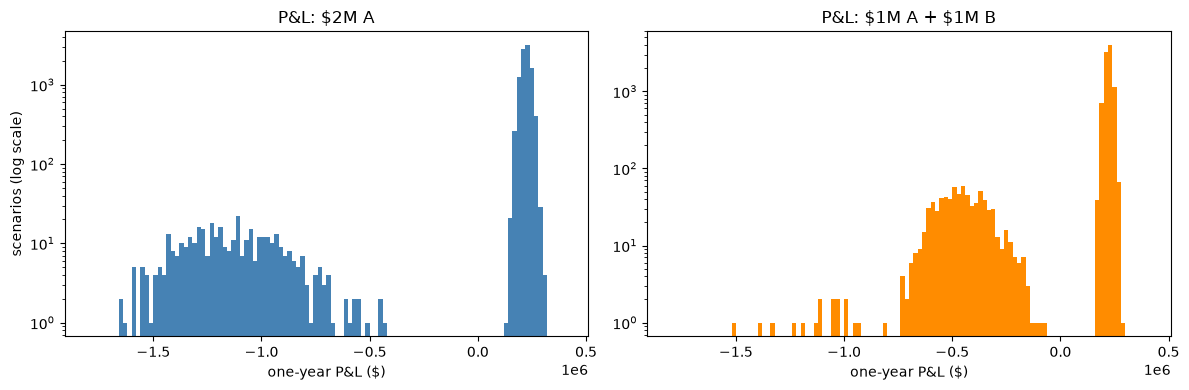

In [24]:
"""Plot the P&L of the two choices. A log y-axis makes the small default cluster visible
next to the ~96% of scenarios where the bond simply pays off."""
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
bins = np.linspace(-1_800_000, 400_000, 111)
for ax, col, color in zip(axes, ["$2M A", "$1M A + $1M B"], ["steelblue", "darkorange"]):
    ax.hist(p3_pnl[col], bins=bins, color=color)
    ax.set_yscale("log")
    ax.set_title("P&L: " + col.replace("$", r"\$"))   # escape $ so matplotlib does not read it as math mode
    ax.set_xlabel("one-year P&L ($)")
axes[0].set_ylabel("scenarios (log scale)")
fig.tight_layout(); fig.savefig("figures/p3_pnl.png", dpi=150)
plt.show()

**What the plot shows.** Each choice has a large spike of small gains (no default: return ≈ +11%, i.e. 90 → 100)
and a separate cluster of large losses. **$2M in A**: one default cluster near −$1M to −$1.6M.
**$1M in each**: a much larger *one-default* cluster near −$450k, and a tiny *two-default* cluster further left.
The distribution is not one bell curve but two or three separate clusters.

### (a) Moments

In [25]:
"""First four moments of each bond's return (four_moments defined in Problem 2)."""
p3_moments = pd.DataFrame({c: four_moments(p3[c]) for c in ["A", "B"]}).T
p3_moments

,mean,std,skewness,excess kurtosis
A,0.0837,0.1360,-4.8232,22.0936
B,0.0850,0.1321,-4.9155,23.0865


Mean ≈ +8.4%, σ ≈ 13.5%, **skew ≈ −4.8, excess kurtosis ≈ 22**. A normal has 0 for both.
A normal VaR uses only the mean and σ, so it spreads the default risk smoothly across a bell curve. The real
distribution is a spike of gains plus a small, distant loss cluster, so a normal VaR will be wrong in both directions:
**too pessimistic at 5%**, where the true 5% quantile is still a gain, and **too optimistic deep in the tail**, where defaults
lose 50–80% and the normal puts almost no probability.

### (b) Counting the large-loss scenarios

In [26]:
"""(not in Library) Count scenarios where each bond loses more than 20%, and the joint events."""
loss_A = p3["A"] < -0.20
loss_B = p3["B"] < -0.20
p3_counts = pd.Series({
    "A loses > 20%": loss_A.sum(),
    "B loses > 20%": loss_B.sum(),
    "at least one loses > 20%": (loss_A | loss_B).sum(),
    "both lose > 20%": (loss_A & loss_B).sum(),
    "5% of scenarios": int(0.05 * len(p3)),
    "1% of scenarios": int(0.01 * len(p3)),
})
print(p3_counts.to_string())
print(f"\nCorrelation of A and B returns: {p3['A'].corr(p3['B']):.4f}  "
      f"(independent defaults would give both ≈ {loss_A.mean() * loss_B.mean() * len(p3):.0f})")

A loses > 20%               406
B loses > 20%               393
at least one loses > 20%    782
both lose > 20%              17
5% of scenarios             500
1% of scenarios             100

Correlation of A and B returns: 0.0022  (independent defaults would give both ≈ 16)


**The counts settle the prediction.**
- A defaults in **406** scenarios (4.06%) and B in 393 (3.93%). Both are **below the 500 scenarios that make up the 5% tail**.
- At least one defaults in **782** scenarios (7.8%), **above** 500. Both default in only 17 scenarios, consistent with independence.

**VaR prediction: diversification *raises* VaR.**
- *Concentrated ($2M A):* the 5% quantile is the 500th worst scenario. Only 406 scenarios are defaults, so the
  500th worst is a **no-default** scenario, i.e. still a *gain*. VaR will be **negative** (a profit).
- *Diversified:* 782 scenarios have at least one default, so the 500th worst is a **one-default** scenario.
  Losing about half of one $1M bond while the other earns about 11% is a loss of roughly −$450k. VaR will be about **+$400k**.

**ES prediction: diversification *lowers* ES.**
- *Concentrated:* the worst 500 scenarios contain all 406 defaults on the full $2M, so the average loss is very large (about −$900k).
- *Diversified:* the worst 500 are almost all one-default scenarios at about −$450k (plus 17 double defaults), so the average is
  much smaller. ES looks at the *size* of the tail, not just where it starts, and the size is roughly halved.

## Fit

In [27]:
def historical_es(x: pd.Series, alpha: float = 0.05) -> float:
    """(not in Library) Historical ES: minus the mean of all outcomes at or below the empirical α-quantile.

    Convention: the cutoff is the same numpy-interpolated quantile used by `historical_var`, so ES ≥ VaR always.
    """
    q = np.quantile(x, alpha)
    return float(-x[x <= q].mean())


def historical_var_es_table(pnl: pd.DataFrame, alpha: float) -> pd.DataFrame:
    """Historical VaR and ES (positive = loss, in $) for every P&L column."""
    return pd.DataFrame({
        f"VaR {alpha:.0%}": {c: historical_var(pnl[c], alpha) for c in pnl},
        f"ES {alpha:.0%}": {c: historical_es(pnl[c], alpha) for c in pnl},
    })

In [28]:
"""(c) Historical VaR and ES at 5%. A negative VaR means the 5% worst outcome is still a profit."""
p3_hist_5 = historical_var_es_table(p3_pnl, 0.05)
p3_hist_5.map("${:,.0f}".format)

,VaR 5%,ES 5%
$1M A,"$-84,570","$443,628"
$1M B,"$-86,063","$419,587"
$2M A,"$-169,140","$887,257"
$1M A + $1M B,"$414,604","$541,997"


In [29]:
"""(d) Normal VaR from each P&L's sample mean and std, via the Library (VaR Absolute = -(μ + z_α σ))."""
p3_normal_5 = pd.Series({c: calculate_var(p3_pnl[c], distribution="normal", alpha=0.05)["VaR Absolute"]
                         for c in p3_pnl}, name="Normal VaR 5%")
p3_normal_1 = pd.Series({c: calculate_var(p3_pnl[c], distribution="normal", alpha=0.01)["VaR Absolute"]
                         for c in p3_pnl}, name="Normal VaR 1%")   # shown for comparison in (h)
pd.concat([p3_normal_5, p3_hist_5["VaR 5%"].rename("Historical VaR 5%")], axis=1).map("${:,.0f}".format)

,Normal VaR 5%,Historical VaR 5%
$1M A,"$139,971","$-84,570"
$1M B,"$132,277","$-86,063"
$2M A,"$279,941","$-169,140"
$1M A + $1M B,"$143,466","$414,604"


In [30]:
"""(e) Historical VaR and ES at 1%."""
p3_hist_1 = historical_var_es_table(p3_pnl, 0.01)
pd.concat([p3_hist_1, p3_normal_1], axis=1).map("${:,.0f}".format)

,VaR 1%,ES 1%,Normal VaR 1%
$1M A,"$649,701","$709,548","$232,645"
$1M B,"$640,393","$700,805","$222,303"
$2M A,"$1,299,403","$1,419,096","$465,291"
$1M A + $1M B,"$598,123","$716,408","$272,811"


## Reconcile

### (f) Subadditivity at 5%

In [31]:
"""A risk measure ρ is subadditive if ρ(A + B) ≤ ρ(A) + ρ(B): combining positions never adds risk."""
for measure in ["VaR 5%", "ES 5%"]:
    stand_alone = p3_hist_5.loc["$1M A", measure] + p3_hist_5.loc["$1M B", measure]
    combined = p3_hist_5.loc["$1M A + $1M B", measure]
    verdict = "holds" if combined <= stand_alone else "VIOLATED"
    print(f"{measure}: ρ(A)+ρ(B) = ${stand_alone:,.0f}   ρ(A+B) = ${combined:,.0f}   -> subadditivity {verdict}")

VaR 5%: ρ(A)+ρ(B) = $-170,633   ρ(A+B) = $414,604   -> subadditivity VIOLATED
ES 5%: ρ(A)+ρ(B) = $863,216   ρ(A+B) = $541,997   -> subadditivity holds


**VaR violates subadditivity, and ES does not.** Both predictions from (b) held.

**Mechanism.** VaR only asks *where* the α-quantile falls, not how bad things are beyond it. Each bond's default
probability (about 4%) is just under 5%, so on its own each default sits *beyond* the 5% cutoff and VaR ignores it: each
bond's stand-alone VaR is a gain (≈ −$85k). Combining two independent bonds nearly doubles the chance that *something*
defaults (4% → 7.8%), which pushes a default scenario *inside* the 5% cutoff, so VaR now counts it (+$415k).
Diversification shrank each loss (−$450k instead of −$900k) but made *some* loss more likely, and VaR only sees the probability.
ES averages the whole tail, so it gives credit for the smaller losses: $542k against $887k for the concentrated bet. ES is
coherent and always subadditive, and this example shows why that matters.

### (g) What the normal VaR says
The normal VaR favours the **diversified** portfolio ($143k vs $280k for $2M in A). That is the right choice (the ES agrees),
but for the wrong reason. The normal model sees only means and standard deviations: two uncorrelated bonds have
σ smaller by about √2, so it reports less risk. It never notices that the default probability crossed the
5% line. Its single-bond number is also wrong: +$140k where the true 5% outcome is a $85k *gain*. It reaches the right
choice by averaging away the shape of the distribution, which happens to be the very thing that makes VaR fail here, so the right answer is luck.

### (h) Why the VaR result flips at 1%
At 1% the cutoff is the **100th worst** scenario. Now 406 defaults (> 100) lie inside the tail for $2M in A, so
its VaR is about $1.30M (a default on the full $2M). For the diversified portfolio, only 17 double defaults lie beyond the cutoff
(< 100), so the 100th worst is a single default and VaR is about $598k. **Diversification wins again at 1%, and subadditivity holds.**

**When VaR fails:** it fails when the probability of a large loss **sits between α and the probability of the combined event**,
here between about 4% (one bond) and 7.8% (either bond). Below α each risk is hidden. Combining them pushes the total over α, and VaR
suddenly sees it. The failure appears at confidence levels where rare, severe events (defaults, jumps) are *just*
rare enough to be ignored. A risk limit at that α encourages concentrating in exactly that kind of risk, so the
VaR level should be set beyond the event probabilities that matter, or ES should be used.

# Problem 4 — Gaussian or t Copula

1,000 days of returns for `X1`–`X3`; $1M in each.

## Predict

### (a) Moments and the choice of margin

In [32]:
"""Load the data and compute the four moments (four_moments from Problem 2)."""
from Risk_Library import (fit_normal_distribution, t_distribution_aicc, kendall_correlation_matrix,
                          t_copula_tail_dependence, gaussian_copula_log_likelihood, fit_t_copula)
from utils import aicc            # Library helper (not re-exported by Risk_Library)
from scipy.special import gammaln

p4 = pd.read_csv("problem4.csv")
p4_n, p4_k = p4.shape
pd.DataFrame({c: four_moments(p4[c]) for c in p4}).T

,mean,std,skewness,excess kurtosis
X1,0.0003,0.0119,-0.0342,-0.1171
X2,-0.0003,0.0162,-0.6150,7.1250
X3,0.0009,0.0100,0.0741,2.8741


In [33]:
"""Check whether the extreme moments depend on a single observation: drop each series' largest
absolute deviation and recompute skewness and excess kurtosis."""
rows = {}
for c in p4:
    x = p4[c]
    i_max = (x - x.mean()).abs().idxmax()              # most extreme day for this series
    x_drop = x.drop(i_max)
    rows[c] = {
        "most extreme return": x[i_max],
        "z-score": (x[i_max] - x.mean()) / x.std(),
        "skew (all)": stats.skew(x, bias=False),
        "skew (drop 1)": stats.skew(x_drop, bias=False),
        "ex. kurt (all)": stats.kurtosis(x, bias=False),
        "ex. kurt (drop 1)": stats.kurtosis(x_drop, bias=False),
    }
pd.DataFrame(rows).T

,most extreme return,z-score,skew (all),skew (drop 1),ex. kurt (all),ex. kurt (drop 1)
X1,-0.0400,-3.3846,-0.0342,-0.0055,-0.1171,-0.1876
X2,-0.1429,-8.8235,-0.6150,0.0559,7.1250,1.7247
X3,-0.0612,-6.2018,0.0741,0.3132,2.8741,1.7307


**From the moments alone:**
- **X1**: skew ≈ 0, excess kurtosis ≈ −0.1 → **normal**.
- **X2**: excess kurtosis **7.1** and skew −0.6 look out of place. One day, a **−14.3% return (an 8.8σ move)**, drives
  almost all of it. Without that day kurtosis falls to 1.7 and skew to +0.06. Even 1.7 is clearly fat-tailed for 1,000
  observations (SE ≈ √(24/1000) ≈ 0.15), so → **t**, but its fitted ν will be heavily influenced by that one day.
- **X3**: excess kurtosis 2.9 (1.7 without its largest day) → **t**.

### (b) Rank scatter plots and joint-tail counts

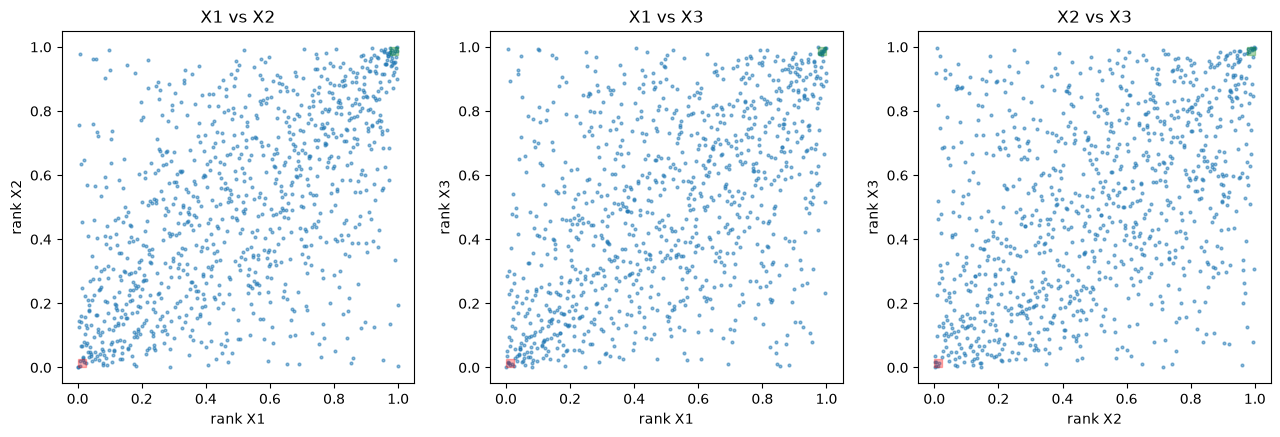

In [34]:
"""Pseudo-observations: ranks scaled into (0,1) with rank/(n+1), so no point sits exactly at 0 or 1."""
p4_ranks = p4.rank() / (p4_n + 1)
p4_pairs = [("X1", "X2"), ("X1", "X3"), ("X2", "X3")]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (a, b) in zip(axes, p4_pairs):
    ax.scatter(p4_ranks[a], p4_ranks[b], s=4, alpha=0.5)
    # Shade the joint worst-2.5% and best-2.5% boxes that are counted below.
    ax.add_patch(plt.Rectangle((0, 0), 0.025, 0.025, color="red", alpha=0.3))
    ax.add_patch(plt.Rectangle((0.975, 0.975), 0.025, 0.025, color="green", alpha=0.3))
    ax.set_xlabel(f"rank {a}"); ax.set_ylabel(f"rank {b}"); ax.set_title(f"{a} vs {b}")
    ax.set_aspect("equal")
fig.tight_layout(); fig.savefig("figures/p4_rank_scatter.png", dpi=150)
plt.show()

In [35]:
def joint_tail_counts(u: pd.DataFrame, pairs, q: float = 0.025) -> pd.DataFrame:
    """(not in Library) For each pair, count days where BOTH sit in their own worst q (u <= q)
    and, separately, both in their own best q (u > 1 - q)."""
    return pd.DataFrame({
        f"{a}-{b}": {"both worst 2.5%": int(((u[a] <= q) & (u[b] <= q)).sum()),
                     "both best 2.5%": int(((u[a] > 1 - q) & (u[b] > 1 - q)).sum())}
        for a, b in p4_pairs
    }).T


p4_tail_data = joint_tail_counts(p4_ranks, p4_pairs)
print(f"Expected under independence: {p4_n} × 0.025² = {p4_n * 0.025**2:.3f} days per pair per tail")
p4_tail_data

Expected under independence: 1000 × 0.025² = 0.625 days per pair per tail


,both worst 2.5%,both best 2.5%
X1-X2,6,8
X1-X3,7,12
X2-X3,6,9


**What the plots and counts show.** Every pair is clearly positively dependent: the cloud runs along the diagonal
(Pearson ρ ≈ 0.47–0.55). Independence would put only **0.6 days** in each corner box, but we see **6–12**, so most of
that excess is just the ordinary positive correlation. Correlation alone does not answer the copula question. What matters is
whether the corners are *tighter* than the middle: in the scatter plots the points near (0,0) and (1,1) bunch
along the diagonal more closely than the points in the center. Both corners are crowded, upper (8–12) as well as lower (6–7), so the
pattern is **symmetric**.

**Prediction: the t copula wins.** Its symmetric tail dependence creates exactly this kind of joint clustering in both corners, which a
Gaussian copula cannot (its tail dependence is 0). I will check the size of the effect against what a Gaussian copula
with the same correlation would imply, in (f).

## Fit

### (c) Margins: normal vs t by AICc

In [36]:
"""Fit both distributions to each margin and compare AICc (lower is better).
Normal: 2 parameters, log likelihood at the MLE (σ with ddof=0). t: 3 parameters, Library MLE."""
aicc_rows, p4_t_fits, p4_n_fits = {}, {}, {}
for c in p4:
    x = p4[c]
    ll_norm = stats.norm.logpdf(x, x.mean(), x.std(ddof=0)).sum()
    p4_t_fits[c] = fit_t_distribution(x)
    p4_n_fits[c] = fit_normal_distribution(x)
    aicc_rows[c] = {
        "AICc normal": aicc(ll_norm, num_params=2, num_obs=p4_n),
        "AICc t": t_distribution_aicc(x, p4_t_fits[c]),
        "t nu": p4_t_fits[c]["nu"],
    }
p4_aicc = pd.DataFrame(aicc_rows).T
p4_aicc["chosen"] = np.where(p4_aicc["AICc normal"] <= p4_aicc["AICc t"], "normal", "t")
p4_aicc

,AICc normal,AICc t,t nu,chosen
X1,-6022.5365,-6020.5245,9.8844e+08,normal
X2,-5408.4940,-5518.1848,5.2715e+00,t
X3,-6365.6912,-6428.0155,6.0949e+00,t


As predicted: **X1 → normal**. Its t fit drives ν to infinity, i.e. it *is* a normal, and pays an AICc penalty for the
extra parameter. **X2 → t (ν ≈ 5.3)** and **X3 → t (ν ≈ 6.1)**, both with large AICc gains (110 and 62 points).

### (d) Uniforms, Kendall-τ correlation, Gaussian and t copula fits

In [37]:
"""Build the chosen marginal distributions as frozen scipy objects, so cdf/ppf work the same either way."""
p4_margins = {}
for c in p4:
    if p4_aicc.loc[c, "chosen"] == "normal":
        p = p4_n_fits[c]
        p4_margins[c] = stats.norm(loc=p["mu"], scale=p["sigma"])
    else:
        p = p4_t_fits[c]
        p4_margins[c] = stats.t(df=p["nu"], loc=p["mu"], scale=p["sigma"])

# Probability integral transform: each series through its own fitted CDF -> approximately Uniform(0,1).
p4_U = pd.DataFrame({c: p4_margins[c].cdf(p4[c]) for c in p4})

# Copula correlation from Kendall's tau via rho = sin(pi*tau/2) (Library, includes a PSD check/repair).
# tau is rank-based, so it is the same whether computed on returns or on the uniforms.
p4_R = kendall_correlation_matrix(p4)
p4_R

,X1,X2,X3
X1,1.0000,0.5833,0.5029
X2,0.5833,1.0000,0.4644
X3,0.5029,0.4644,1.0000


In [38]:
def gaussian_copula_logpdf(U: np.ndarray, R: np.ndarray) -> np.ndarray:
    """(Library gives only the total, with all-t margins) Per-day Gaussian copula log density.

    z = Φ⁻¹(u);  log c(u) = -½ log|R| - ½ z'(R⁻¹ - I) z.
    """
    z = stats.norm.ppf(U)
    R_inv = np.linalg.inv(R)
    _, logdet = np.linalg.slogdet(R)
    quad = np.einsum("ij,jk,ik->i", z, R_inv, z) - np.sum(z * z, axis=1)
    return -0.5 * logdet - 0.5 * quad


def t_copula_logpdf(U: np.ndarray, R: np.ndarray, nu: float) -> np.ndarray:
    """(Library gives only the total, with all-t margins) Per-day t copula log density.

    z = t_ν⁻¹(u);  log c(u) = log f_multivariate-t(z; R, ν) - Σ_i log f_t(z_i; ν).
    """
    k = R.shape[0]
    z = stats.t.ppf(U, df=nu)
    R_inv = np.linalg.inv(R)
    _, logdet = np.linalg.slogdet(R)
    m = np.einsum("ij,jk,ik->i", z, R_inv, z)
    log_joint = (gammaln((nu + k) / 2) - gammaln(nu / 2) - 0.5 * k * np.log(nu * np.pi)
                 - 0.5 * logdet - 0.5 * (nu + k) * np.log1p(m / nu))
    return log_joint - stats.t.logpdf(z, df=nu).sum(axis=1)


U_arr, R_arr = p4_U.values, p4_R.values

# Gaussian copula: R is fixed from Kendall's tau, so there is nothing left to optimize.
ll_gauss_days = gaussian_copula_logpdf(U_arr, R_arr)

# t copula: R fixed from Kendall's tau; maximize the log likelihood over nu alone (profile likelihood).
from scipy.optimize import minimize_scalar
nu_fit = minimize_scalar(lambda nu: -t_copula_logpdf(U_arr, R_arr, nu).sum(),
                         bounds=(2.0001, 200), method="bounded", options={"xatol": 1e-8})
p4_nu = nu_fit.x
ll_t_days = t_copula_logpdf(U_arr, R_arr, p4_nu)

# Cross-check against the Library (it fits t margins everywhere; X1's t has nu -> inf, i.e. normal, so totals should agree).
print(f"Gaussian LL: mine {ll_gauss_days.sum():.3f}  vs Library {gaussian_copula_log_likelihood(p4):.3f}")
print(f"t copula nu: mine {p4_nu:.4f}  vs Library {fit_t_copula(p4)['nu']:.4f}")

Gaussian LL: mine 350.454  vs Library 350.440
t copula nu: mine 3.6584  vs Library 3.6599


In [39]:
"""Information criteria. Parameter-count convention: the 3 correlations count for BOTH copulas
(Gaussian K=3, t K=4). Only the difference matters for the comparison; the Library's compare_copulas
counts only the extra nu (K=0 vs 1), which gives the same ranking."""
def copula_ic(ll: float, K: int, n: int) -> dict:
    """Log likelihood, AICc (Library helper) and BIC = -2LL + K ln n."""
    return {"log likelihood": ll, "K": K, "AICc": aicc(ll, K, n), "BIC": -2 * ll + K * np.log(n)}

p4_ic = pd.DataFrame({
    "Gaussian": {**copula_ic(ll_gauss_days.sum(), 3, p4_n), "nu_hat": np.inf},
    "t": {**copula_ic(ll_t_days.sum(), 4, p4_n), "nu_hat": p4_nu},
}).T
p4_ic

,log likelihood,K,AICc,BIC,nu_hat
Gaussian,350.4536,3.0,-694.8831,-680.1839,inf
t,451.9987,4.0,-895.9572,-876.3664,3.6584


### (e) Simulate 100,000 days from each copula

In [40]:
"""Simulate both copulas from the SAME standard normal draws (common random numbers), so differences
between them come from the copula, not from Monte Carlo noise. Then map the uniforms through the fitted margins."""
P4_NSIM, P4_SEED = 100_000, 545
rng = np.random.default_rng(P4_SEED)
L = cholesky_psd(p4_R).values                                     # Library Cholesky: R = L L'
Z = rng.standard_normal((P4_NSIM, p4_k)) @ L.T                    # correlated N(0, R)

U_sim_gauss = stats.norm.cdf(Z)                                    # Gaussian copula uniforms
W = rng.chisquare(p4_nu, P4_NSIM)                                  # multivariate t = normal / sqrt(chi²/ν)
U_sim_t = stats.t.cdf(Z / np.sqrt(W / p4_nu)[:, None], df=p4_nu)   # t copula uniforms


def uniforms_to_portfolio_pnl(U: np.ndarray) -> np.ndarray:
    """Inverse-CDF each column through its fitted margin, then sum $1M × return across the three assets."""
    returns = np.column_stack([p4_margins[c].ppf(U[:, i]) for i, c in enumerate(p4.columns)])
    return 1_000_000 * returns.sum(axis=1)


p4_pnl = {
    "Gaussian copula": uniforms_to_portfolio_pnl(U_sim_gauss),
    "t copula": uniforms_to_portfolio_pnl(U_sim_t),
    "Historical": 1_000_000 * p4.sum(axis=1).values,
}
p4_risk = pd.DataFrame({
    name: {"VaR 5%": historical_var(x, 0.05), "ES 5%": historical_es(pd.Series(x), 0.05),
           "VaR 1%": historical_var(x, 0.01), "ES 1%": historical_es(pd.Series(x), 0.01)}
    for name, x in p4_pnl.items()
}).T
p4_risk.map("${:,.0f}".format)

,VaR 5%,ES 5%,VaR 1%,ES 1%
Gaussian copula,"$49,420","$66,393","$76,246","$93,839"
t copula,"$48,876","$68,372","$79,626","$102,806"
Historical,"$47,541","$65,699","$67,264","$102,424"


### (f) Joint-tail days implied by each copula (per 1,000 days)

In [41]:
"""Simulated copula uniforms ARE each margin's own quantile level, so 'both in their own worst 2.5%'
is simply u_i <= 0.025 and u_j <= 0.025. Scale the frequency to a 1,000-day sample."""
def implied_tail_days(U: np.ndarray) -> pd.DataFrame:
    u = pd.DataFrame(U, columns=p4.columns)
    return joint_tail_counts(u, p4_pairs) * 1000 / len(u)

p4_tail_compare = pd.concat({
    "Data": p4_tail_data,
    "Gaussian copula": implied_tail_days(U_sim_gauss),
    "t copula": implied_tail_days(U_sim_t),
}, axis=1)
p4_tail_compare.loc["average"] = p4_tail_compare.mean()
p4_tail_compare

Data                Gaussian copula                       t copula               
        both worst 2.5% both best 2.5% both worst 2.5% both best 2.5% both worst 2.5% both best 2.5%
X1-X2            6.0000         8.0000          6.3900         6.3800            9.62         9.9700
X1-X3            7.0000        12.0000          4.6100         4.6800            8.11         8.4900
X2-X3            6.0000         9.0000          4.5500         4.4900            7.74         7.9200
average          6.3333         9.6667          5.1833         5.1833            8.49         8.7933

## Reconcile

### (g) Which copula wins, and by how much?

In [42]:
"""Differences in fit statistics (t minus Gaussian; negative AICc/BIC = t is better)."""
print(f"Log-likelihood gain of t over Gaussian: {p4_ic.loc['t', 'log likelihood'] - p4_ic.loc['Gaussian', 'log likelihood']:.1f}")
print(f"ΔAICc (t - Gaussian): {p4_ic.loc['t', 'AICc'] - p4_ic.loc['Gaussian', 'AICc']:.1f}")
print(f"ΔBIC  (t - Gaussian): {p4_ic.loc['t', 'BIC'] - p4_ic.loc['Gaussian', 'BIC']:.1f}")
# Likelihood-ratio view: Gaussian is the nu -> inf limit of t, so 2ΔLL is roughly chi-square(1) (a boundary case, rough).
print(f"2ΔLL = {2 * (p4_ic.loc['t', 'log likelihood'] - p4_ic.loc['Gaussian', 'log likelihood']):.0f} vs χ²(1) 1% critical value 6.6")

Log-likelihood gain of t over Gaussian: 101.5
ΔAICc (t - Gaussian): -201.1
ΔBIC  (t - Gaussian): -196.2
2ΔLL = 203 vs χ²(1) 1% critical value 6.6


**The t copula wins by a wide margin**, as predicted: about +101.5 in log likelihood, which is a drop of about 200 in AICc and 196 in BIC
for one extra parameter. ν̂ ≈ 3.7 is a *very* heavy-tailed dependence structure.

**Joint tails: a mixed picture, and not fully what I predicted.** Averaged over the three pairs:

| | data | Gaussian | t |
|---|---|---|---|
| both worst 2.5% | 6.3 | 5.2 | 8.5 |
| both best 2.5% | 9.7 | 5.2 | 8.8 |

- **Upper tail:** the t copula clearly fits better, and the Gaussian under-predicts every pair (8, 12, 9 observed vs about 6.4, 4.7, 4.5).
- **Lower tail:** the data (6, 7, 6) sits *between* the two copulas and is in fact slightly closer to the Gaussian. The t
  over-predicts joint crashes here by about 2 days per pair.

So the data's tail clustering is **asymmetric**: stronger on the upside than on the downside. Both copulas are symmetric, so each misses
one side. The t gets the upper corner right and overshoots the lower one; the Gaussian gets the lower one roughly right and misses the upper one.
In (b) I described the pattern as symmetric, but the counts show it is not.

With only 6–12 events per cell (Poisson SE about 2.5–3.5), the lower-tail gap between data and t is within about 1 SE, so this is suggestive rather than
conclusive. Still, the large likelihood win does *not* come mainly from the t copula matching the joint crashes, and (i) shows where it does come from.
A risk caveat follows: because the t copula over-predicts joint crashes in this sample, its 1% ES is the more conservative number.

### (h) Which risk number moves most?

In [43]:
"""Percent change in each risk number when switching from the Gaussian to the t copula."""
change = (p4_risk.loc["t copula"] / p4_risk.loc["Gaussian copula"] - 1).rename("t vs Gaussian")
change.map("{:+.1%}".format).to_frame()

,t vs Gaussian
VaR 5%,-1.1%
ES 5%,+3.0%
VaR 1%,+4.4%
ES 1%,+9.6%


**The 1% ES moves most (+9–10%)**, followed by the 1% VaR (+4%). The 5% VaR barely moves (about −1%). The historical 1% ES
(about \$102k) agrees with the t copula (about \$103k), not the Gaussian (about \$94k).

**Why the 5% VaR barely moves.** Both copulas use the *same* margins and the *same* rank correlation R. The 5% quantile of
the portfolio sits in the main body of the distribution, where it is governed mostly by the overall correlation level, which the two copulas share by
construction. The two copulas differ mainly in the **joint extremes**: the t puts more mass on all three assets crashing together
and slightly *less* on moderate joint moves (to keep the same Kendall τ), so the 5% quantile barely shifts and even dips a little.
The extra joint-crash mass only shows up beyond the 5% line, which is why the 1% numbers move and the 1% ES, which averages
the deepest scenarios, moves most.

### (i) Where does the likelihood gain come from?

In [44]:
"""Per-day contribution ℓ_t - ℓ_Gauss, split by whether ANY series sits in its outer 5% (either side).
Outer/inner is judged on each series' own empirical rank (same pseudo-observations as part (b))."""
p4_diff = ll_t_days - ll_gauss_days
inner = ((p4_ranks > 0.05) & (p4_ranks < 0.95)).all(axis=1).values   # no series in its outer 5% on either side

p4_split = pd.DataFrame({
    "days": [inner.sum(), (~inner).sum(), p4_n],
    "sum of ℓ_t - ℓ_G": [p4_diff[inner].sum(), p4_diff[~inner].sum(), p4_diff.sum()],
}, index=["no series in outer 5%", "at least one in outer 5%", "total"])
p4_split["share of total"] = p4_split["sum of ℓ_t - ℓ_G"] / p4_diff.sum()
p4_split

,days,sum of ℓ_t - ℓ_G,share of total
no series in outer 5%,784,49.8438,0.4909
at least one in outer 5%,216,51.7013,0.5091
total,1000,101.5451,1.0000


**About half (≈ 49%) of the t copula's likelihood advantage comes from the 784 "ordinary" days** where no
asset is in its outer 5%. The 216 days that touch a tail supply the other half. Per day, tail days count
more (about 0.24 vs 0.06 log-likelihood units per day), but there are far fewer of them.

**What this says about the information criterion.** AICc/BIC score the copula density over the **entire unit cube**. A
t copula with ν ≈ 3.7 also has a different *shape in the middle*: it concentrates more mass along the diagonal near
the center and puts a different spread on moderate moves. Many ordinary days fit that shape better. So "t wins on AICc" is not
the same as "t gets the tails right". Half of the evidence is about the body of the distribution, which is not the part that drives
ES. To judge tail behaviour directly, we need tail-specific checks: the joint-tail counts in (f), tail dependence, and how well
the 1% ES backtests.

### (j) Tail dependence for the most correlated pair

In [45]:
"""Library: lower-tail dependence λ = 2 t_{ν+1}( -sqrt((ν+1)(1-ρ)/(1+ρ)) ) for every pair under the fitted t copula.
(The t copula is symmetric, so upper-tail dependence is identical.)"""
p4_lambda = t_copula_tail_dependence(p4_R, p4_nu)
p4_lambda["pair"] = [f"{p4.columns[i - 1]}-{p4.columns[j - 1]}" for i, j in zip(p4_lambda["I"], p4_lambda["J"])]
p4_lambda["Gaussian λ"] = 0.0          # Gaussian copula: λ = 0 for any ρ < 1
p4_lambda.set_index("pair")[["Rho", "Lambda", "Gaussian λ"]]

,Rho,Lambda,Gaussian λ
pair,,,
X1-X2,0.5833,0.3220,0.0
X1-X3,0.5029,0.2733,0.0
X2-X3,0.4644,0.2525,0.0


The most correlated pair is **X1–X2 (ρ ≈ 0.58)**. Under the fitted t copula (ν ≈ 3.7) its tail dependence is
**λ ≈ 0.32**: given that one asset has an extreme crash, there is roughly a 1-in-3 chance the other does too, *no matter
how far into the tail we go*. Under the Gaussian copula **λ = 0** for any ρ < 1: joint crashes become independent in the limit.
That difference does not show up at the 5% level but does at 1%, which is why the 1% ES is the risk number that
moves most.

# Problem 5 — Model Based Simulation and Residual Correlation

Model: $r_i = \alpha_i + \beta_i r_{MKT} + \epsilon_i$, market and errors normal, zero expected returns.
P1 = +\$1M A, +\$1M B. P2 = +\$1M A, −\$1M B.

## Predict

### (a) Does treating $\epsilon_A \perp \epsilon_B$ overstate or understate VaR?

With dollar weights $w = (w_A, w_B)$ the portfolio return variance is (Week 2, $w^\top \Sigma w$):

$$\sigma_P^2 = (w_A\beta_A + w_B\beta_B)^2\sigma_M^2 + w_A^2\sigma_{\epsilon_A}^2 + w_B^2\sigma_{\epsilon_B}^2 + 2\,w_A w_B\,\mathrm{Cov}(\epsilon_A,\epsilon_B).$$

The shortcut sets the last term to zero. If the stocks share an industry the market does not capture, then $\mathrm{Cov}(\epsilon_A,\epsilon_B) > 0$.

- **P1** ($w_A w_B = +1$): the dropped term is **positive**, so the shortcut **understates** P1's variance and VaR.
- **P2** ($w_A w_B = -1$): the dropped term is **negative** (a long/short pair hedges the shared industry move), so the shortcut **overstates** P2's VaR.

**Which is more exposed?** In P2 the market exposure is $(\beta_A - \beta_B)$, close to zero if the betas are similar, so P2's
variance is *mostly* residual and the covariance term is a large share of it. In P1 the market term $(\beta_A+\beta_B)^2\sigma_M^2$
dominates and dilutes the error. So I expect **P2 to move much more in percentage terms**.

## Fit

### (b) Regressions

In [46]:
"""Returns via the Library, then OLS of each stock on the market."""
p5_prices = pd.read_csv("problem5.csv")
p5_ret = return_calculate(p5_prices, method="arithmetic", date_column="Day").drop(columns="Day")


def ols_market_model(y: pd.Series, x: pd.Series) -> dict:
    """(not in Library — Library has only a t-error regression) OLS fit of y = α + β x + ε.

    Solved by least squares on the design matrix [1, x]. Returns α, β and the residual series.
    """
    X = np.column_stack([np.ones(len(x)), x.values])
    (alpha, beta), *_ = np.linalg.lstsq(X, y.values, rcond=None)
    resid = y - (alpha + beta * x)
    return {"alpha": alpha, "beta": beta, "resid": resid}


p5_fit = {s: ols_market_model(p5_ret[s], p5_ret["MKT"]) for s in ["A", "B"]}
p5_resid = pd.DataFrame({s: p5_fit[s]["resid"] for s in p5_fit})

# Convention: ddof=1 for every variance/covariance in this problem (residuals, market, sample cov in (d)),
# so the model-implied covariance and the sample covariance are on the same footing.
p5_params = pd.DataFrame({
    s: {"alpha": p5_fit[s]["alpha"], "beta": p5_fit[s]["beta"], "resid std": p5_resid[s].std()}
    for s in p5_fit
}).T
print(p5_params.to_string())
print(f"\nCorrelation between residuals ε_A, ε_B: {p5_resid['A'].corr(p5_resid['B']):.4f}")
print(f"Correlation of residuals with the market (OLS forces ≈ 0): "
      f"{p5_resid['A'].corr(p5_ret['MKT']):.1e}, {p5_resid['B'].corr(p5_ret['MKT']):.1e}")

    alpha    beta  resid std
A  0.0002  1.0353     0.0129
B  0.0003  0.9354     0.0115

Correlation between residuals ε_A, ε_B: 0.6983
Correlation of residuals with the market (OLS forces ≈ 0): -4.2e-16, -1.8e-16


Both stocks have β ≈ 1 (1.035 and 0.935), with small α's (2–3 bp/day). The residual correlation is **0.70**, a strong
shared component the market does not explain, exactly the "same industry" case from (a).

### (c) Simulate the factor model with full vs diagonal residual covariance

In [47]:
"""Simulate [r_MKT, ε_A, ε_B] jointly normal with the Library's simulate_normal.
Zero expected returns: market mean 0 and α set to 0 in the simulated returns (the fitted α is a mean we are told to ignore).
The SAME seed is used for both runs (common random numbers), so the only difference is the off-diagonal term."""
from Risk_Library import simulate_normal

P5_NSIM, P5_SEED = 100_000, 545
var_mkt = p5_ret["MKT"].var()
cov_resid_full = p5_resid.cov()
cov_resid_diag = pd.DataFrame(np.diag(np.diag(cov_resid_full)), index=cov_resid_full.index, columns=cov_resid_full.columns)

p5_weights = {"P1": pd.Series({"A": 1_000_000, "B": 1_000_000}),
              "P2": pd.Series({"A": 1_000_000, "B": -1_000_000})}
beta = p5_params["beta"]


def factor_cov(cov_resid: pd.DataFrame) -> pd.DataFrame:
    """(not in Library) Block-diagonal covariance of [MKT, ε_A, ε_B]: market independent of the errors (OLS)."""
    labels = ["MKT"] + list(cov_resid.columns)
    cov = np.zeros((3, 3))
    cov[0, 0] = var_mkt
    cov[1:, 1:] = cov_resid.values
    return pd.DataFrame(cov, index=labels, columns=labels)


def simulate_factor_model_var(cov_resid: pd.DataFrame) -> pd.Series:
    """Simulate the factor model, build r_i = β_i r_MKT + ε_i, and return the 5% VaR ($) of P1 and P2."""
    draws = simulate_normal(factor_cov(cov_resid), num_simulations=P5_NSIM, seed=P5_SEED)
    stock_ret = pd.DataFrame({s: beta[s] * draws["MKT"] + draws[s] for s in ["A", "B"]})
    return pd.Series({p: historical_var(stock_ret @ w, 0.05) for p, w in p5_weights.items()})


p5_var_sim = pd.DataFrame({
    "full residual cov": simulate_factor_model_var(cov_resid_full),
    "diagonal (shortcut)": simulate_factor_model_var(cov_resid_diag),
})
p5_var_sim.map("${:,.0f}".format)

,full residual cov,diagonal (shortcut)
P1,"$50,295","$44,450"
P2,"$15,840","$28,469"


### (d) Delta-normal VaR from the sample covariance of the two stocks

In [48]:
"""Delta normal: σ_P² = w' Σ w with Σ the sample covariance of (A, B) returns; zero mean, so VaR = 1.645 σ_P.
Also compute the same formula analytically for both factor-model covariances, to separate model from Monte Carlo noise."""
cov_AB = p5_ret[["A", "B"]].cov()

def model_implied_cov(cov_resid: pd.DataFrame) -> pd.DataFrame:
    """(not in Library) Factor-model covariance of the stocks: β β' σ_M² + Σ_ε."""
    b = beta[["A", "B"]].values
    return pd.DataFrame(np.outer(b, b) * var_mkt + cov_resid.values, index=["A", "B"], columns=["A", "B"])

p5_compare = pd.DataFrame({
    "delta normal (sample cov)": {p: normal_var(np.sqrt(portfolio_variance(cov_AB, w))) for p, w in p5_weights.items()},
    "factor model, full (analytic)": {p: normal_var(np.sqrt(portfolio_variance(model_implied_cov(cov_resid_full), w))) for p, w in p5_weights.items()},
    "factor model, full (simulated)": p5_var_sim["full residual cov"],
    "factor model, diagonal (analytic)": {p: normal_var(np.sqrt(portfolio_variance(model_implied_cov(cov_resid_diag), w))) for p, w in p5_weights.items()},
    "factor model, diagonal (simulated)": p5_var_sim["diagonal (shortcut)"],
})
p5_compare.map("${:,.0f}".format)

,delta normal (sample cov),"factor model, full (analytic)","factor model, full (simulated)","factor model, diagonal (analytic)","factor model, diagonal (simulated)"
P1,"$50,415","$50,415","$50,295","$44,494","$44,450"
P2,"$15,834","$15,834","$15,840","$28,507","$28,469"


## Reconcile

### (e) Direction and size of the shortcut's error

In [49]:
"""Percent error of the shortcut relative to the full model, and the decomposition of each portfolio's variance."""
shortcut_err = p5_var_sim["diagonal (shortcut)"] / p5_var_sim["full residual cov"] - 1
print("Shortcut VaR vs full model:", shortcut_err.map("{:+.1%}".format).to_dict())

# Variance decomposition per portfolio (in $²), using the formula from (a).
cov_e = cov_resid_full
rows = {}
for p, w in p5_weights.items():
    wA, wB = w["A"], w["B"]
    rows[p] = {
        "market term": (wA * beta["A"] + wB * beta["B"]) ** 2 * var_mkt,
        "own residual terms": wA**2 * cov_e.loc["A", "A"] + wB**2 * cov_e.loc["B", "B"],
        "residual covariance term": 2 * wA * wB * cov_e.loc["A", "B"],
    }
decomp = pd.DataFrame(rows).T
decomp["total"] = decomp.sum(axis=1)
(decomp.div(decomp["total"], axis=0)).map("{:.0%}".format)

Shortcut VaR vs full model: {'P1': '-11.6%', 'P2': '+79.7%'}


,market term,own residual terms,residual covariance term,total
P1,46%,32%,22%,100%
P2,1%,323%,-224%,100%


**Yes, both directions match the prediction.** Ignoring the residual correlation **understates P1** (−11.6%) and
**overstates P2** (+79.7%).

**P2 is far more exposed.** The variance decomposition shows why:
- For **P1**, the market term is the largest piece (46% of variance), own residuals are 32%, and the residual covariance
  term is 22%. Removing it leaves 78% of the variance, so σ falls by only about 12%.
- For **P2**, the betas almost cancel (1.035 − 0.935 = 0.10), so the market term is about 1% of variance and the risk is almost entirely
  residual. The covariance term is **negative** (−224% of the total) and cancels about 70% of the own-residual variance (323%).
  Without it, the variance is 3.2× too large and σ about 1.8× too large. Remove it and the portfolio looks
  far riskier than it is: a well-hedged pair appears to be two unrelated bets.

The hedged, market-neutral book is the one whose risk depends on correctly modelling the residual dependence. That is exactly
where the shortcut gets used most often.

### (f) Full factor model vs delta normal

In [50]:
"""The model-implied covariance with the FULL residual covariance reproduces the sample covariance exactly (ddof=1)."""
print("Sample covariance of (A, B):"); display(cov_AB)
print("Factor model β β' σ_M² + Σ_ε (full):"); display(model_implied_cov(cov_resid_full))
print(f"Max absolute difference: {np.abs(cov_AB.values - model_implied_cov(cov_resid_full).values).max():.2e}")

Sample covariance of (A, B):


,A,B
A,0.0003,0.0002
B,0.0002,0.0002


Factor model β β' σ_M² + Σ_ε (full):


,A,B
A,0.0003,0.0002
B,0.0002,0.0002


Max absolute difference: 5.42e-20


**The full-covariance factor model and the delta-normal VaR agree.** Analytically they agree to floating-point precision, and the
simulated numbers differ only by Monte Carlo noise (well under 1%).

**Why (Week 5).** OLS splits each return into a part explained by the market and a residual that is **uncorrelated with the market by
construction**, in sample and exactly. So

$$\mathrm{Cov}(r) = \beta\beta^\top\sigma_M^2 + \Sigma_\epsilon$$

holds as an algebraic identity in sample. When the market and the stocks are **jointly normal**, the
conditional mean of each stock given the market is exactly linear, OLS is the MLE, and the residuals are normal and independent of the market.
The factor model is then just a *re-parameterisation* of the same multivariate normal that delta-normal VaR uses. With
the full residual covariance it carries the same information, so both give the same σ_P and the same VaR.

**When they stop agreeing:**
- **When the residual covariance is restricted.** The diagonal shortcut in (c) is one example; keeping only some factors, or shrinking Σ_ε, are others.
  This is the main reason factor models are used, and it is exactly the case that breaks P2.
- **When the inputs are not estimated the same way.** Examples: β estimated on a different window, EW-weighted or "adjusted" β's, a market variance
  forecast that differs from the sample variance, or ddof conventions that do not match.
- **When the joint-normal assumption fails.** Examples: fat-tailed or skewed residuals, a non-linear relationship to the market, β's that change
  with the market regime, or volatility clustering. Then simulating non-normal factors or residuals gives a different distribution from the
  delta-normal ellipse, even with matching covariances.
- **When non-zero α's or means are included** in one method but not the other.